# Ir Além 2 — Otimização de recursos com Algoritmo Genético
**FarmTech Solutions · Fase 7 · Grupo 27 · FIAP Inteligência Artificial**
Kauan Maciel Forgiarini — RM 574005 · Wagner Adriano de Souza Silva Junior — RM 569431

## 1. Problema
Na semana analisada a fazenda tem **água limitada** (outorga/reservatório do pivô) e **orçamento limitado**
para manejo. Cada setor dos talhões cadastrados na **Fase 1** pode receber três intervenções: irrigação
suplementar, adubação de cobertura e calagem. Cada uma consome água e/ou dinheiro e traz um ganho esperado
de produtividade (sacas × preço da saca).

Isso é uma **mochila binária com duas restrições** (*multidimensional 0/1 knapsack*):

$$\max \sum_i v_i x_i \quad \text{s.a.} \quad \sum_i a_i x_i \le A, \quad \sum_i c_i x_i \le C, \quad x_i \in \{0,1\}$$

- $v_i$: receita esperada da intervenção (R\$) · $a_i$: água (m³) · $c_i$: custo (R\$)
- $A$: água disponível na semana · $C$: orçamento

Com 36 intervenções há $2^{36} \approx 6{,}9 \times 10^{10}$ combinações, inviável por força bruta.

## 2. Reprodutibilidade
A entrada foi gerada **uma única vez** por `IR-ALEM/src/gerar_entrada_ag.py` (semente 574005, a partir de
`data/fase1_talhoes.csv`) e salva em arquivo. Este notebook **apenas lê** esses arquivos:
- `IR-ALEM/data/ag_entrada_intervencoes.csv`
- `IR-ALEM/data/ag_restricoes.json`

In [1]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Localiza a pasta IR-ALEM tanto rodando localmente quanto no Colab (após clonar o repositório)
BASE = Path.cwd()
while not (BASE / "IR-ALEM").exists() and BASE != BASE.parent:
    BASE = BASE.parent
PASTA = BASE / "IR-ALEM"
DOCS = PASTA / "docs"
DOCS.mkdir(exist_ok=True)

itens = pd.read_csv(PASTA / "data" / "ag_entrada_intervencoes.csv")
restricoes = json.loads((PASTA / "data" / "ag_restricoes.json").read_text(encoding="utf-8"))

valor = itens["receita_rs"].to_numpy(dtype=float)   # v_i
agua = itens["agua_m3"].to_numpy(dtype=float)       # a_i
custo = itens["custo_rs"].to_numpy(dtype=float)     # c_i
A, C = restricoes["agua_disponivel_m3"], restricoes["orcamento_rs"]
N = len(itens)
print(f"{N} intervenções | água disponível {A} m³ de {agua.sum():.0f} | orçamento R$ {C} de R$ {custo.sum():.0f}")
itens.groupby("intervencao")[["agua_m3", "custo_rs", "receita_rs"]].sum()

36 intervenções | água disponível 5650 m³ de 12550 | orçamento R$ 24500 de R$ 61300


,agua_m3,custo_rs,receita_rs
intervencao,,,
adubacao,0,30600,25027
calagem,0,20400,12544
irrigacao,12550,10300,31704


## 3. Referência de qualidade: ótimo exato por programação dinâmica
Como a água é múltiplo de 10 m³ e o custo múltiplo de R\$ 100, é possível calcular o **ótimo exato** com
programação dinâmica em duas dimensões (água × orçamento). Ele serve de régua para medir a qualidade do AG
(*gap* = distância percentual até o ótimo). Em problemas maiores ou com restrições não inteiras essa
técnica deixa de ser viável, e é aí que a meta-heurística se justifica.

In [2]:
def otimo_programacao_dinamica(valor, agua, custo, A, C, ua=10, uc=100):
    """Mochila 0/1 com duas restrições. dp[w, c] = melhor receita usando até w unidades de água e c de custo."""
    W, B = int(A // ua), int(C // uc)
    w_i, c_i = (agua // ua).astype(int), (custo // uc).astype(int)
    dp = np.zeros((W + 1, B + 1))
    escolhas = np.zeros((len(valor), W + 1, B + 1), dtype=bool)
    for i in range(len(valor)):
        candidato = np.full_like(dp, -np.inf)
        candidato[w_i[i]:, c_i[i]:] = dp[:W + 1 - w_i[i], :B + 1 - c_i[i]] + valor[i]
        escolhas[i] = candidato > dp
        dp = np.maximum(dp, candidato)
    # reconstrução da solução
    x, w, c = np.zeros(len(valor), dtype=int), W, B
    for i in range(len(valor) - 1, -1, -1):
        if escolhas[i, w, c]:
            x[i], w, c = 1, w - w_i[i], c - c_i[i]
    return dp[W, B], x

inicio = time.perf_counter()
OTIMO, x_otimo = otimo_programacao_dinamica(valor, agua, custo, A, C)
tempo_pd = time.perf_counter() - inicio
assert (agua @ x_otimo) <= A and (custo @ x_otimo) <= C and np.isclose(valor @ x_otimo, OTIMO)
print(f"Ótimo exato: R$ {OTIMO:,.0f} com {x_otimo.sum()} intervenções "
      f"(água {agua @ x_otimo:.0f}/{A} m³, custo R$ {custo @ x_otimo:.0f}/{C}) em {tempo_pd*1000:.1f} ms")

Ótimo exato: R$ 44,480 com 15 intervenções (água 5650/5650 m³, custo R$ 24400/24500) em 27.3 ms


## 4. Algoritmo genético
**Representação:** cromossomo binário de 36 genes ($x_i = 1$ executa a intervenção $i$).

**Aptidão (fitness):** receita total; soluções que estouram água ou orçamento recebem penalidade proporcional
ao excesso relativo, multiplicada pela receita máxima possível — assim uma solução inviável nunca supera uma
viável, mas ainda guia a busca (diferente de simplesmente zerar a aptidão).

**Parâmetros (justificativa):**

| Parâmetro | Valor | Justificativa |
|---|---|---|
| População | 60 | ≈ 1,7 × nº de genes: diversidade suficiente sem custo alto por geração |
| Gerações | 150 | as curvas de convergência estabilizam antes de 100 gerações nas versões melhores |
| Taxa de cruzamento | 0,85 | valor usual (0,6–0,9) para preservar blocos bons e ainda explorar |
| Taxa de mutação | 1/N ≈ 0,028 por gene | em média 1 bit alterado por filho — recomendação clássica para codificação binária |
| Elitismo | 2 indivíduos | garante que a melhor solução nunca se perde |
| Repetições | 20 sementes por configuração | AG é estocástico: comparar médias e dispersão, não uma única execução |

**Funções estruturantes comparadas** (o enunciado pede alterar `selection()`, `crossover()` ou `mutation()`):

| Configuração | selection() | crossover() | mutation() |
|---|---|---|---|
| **Base** | roleta | 1 ponto | bit-flip |
| Seleção por torneio | **torneio (k=3)** | 1 ponto | bit-flip |
| Cruzamento uniforme | roleta | **uniforme** | bit-flip |
| Mutação com reparo | roleta | 1 ponto | **bit-flip + reparo guloso** |
| Combinada | torneio | uniforme | bit-flip + reparo |

In [3]:
VALOR_MAXIMO = valor.sum()

def fitness(pop):
    """Receita da população inteira (matriz P x N), com penalidade por excesso de água/orçamento."""
    receita = pop @ valor
    excesso = np.maximum(0, pop @ agua - A) / A + np.maximum(0, pop @ custo - C) / C
    return receita - excesso * VALOR_MAXIMO

def viavel(x):
    return (x @ agua) <= A and (x @ custo) <= C

def populacao_inicial(rng, tamanho):
    # probabilidade baixa de 1 para começar perto da região viável (restrições apertadas)
    return (rng.random((tamanho, N)) < 0.3).astype(int)

# ---------------------------- selection() ----------------------------
def selection_roleta(pop, apt, rng):
    """Roleta: probabilidade proporcional à aptidão (deslocada para ficar positiva)."""
    pesos = apt - apt.min() + 1e-9
    return pop[rng.choice(len(pop), p=pesos / pesos.sum())]

def selection_torneio(pop, apt, rng, k=3):
    """Torneio: sorteia k indivíduos e escolhe o melhor (pressão seletiva controlada por k)."""
    competidores = rng.choice(len(pop), size=k, replace=False)
    return pop[competidores[np.argmax(apt[competidores])]]

# ---------------------------- crossover() ----------------------------
def crossover_um_ponto(pai, mae, rng):
    ponto = rng.integers(1, N)
    return np.concatenate([pai[:ponto], mae[ponto:]]), np.concatenate([mae[:ponto], pai[ponto:]])

def crossover_uniforme(pai, mae, rng):
    """Cada gene vem de um dos pais com 50%: não depende da ordem dos itens no cromossomo."""
    mascara = rng.random(N) < 0.5
    return np.where(mascara, pai, mae), np.where(mascara, mae, pai)

# ---------------------------- mutation() -----------------------------
def mutation_bitflip(x, rng, taxa):
    inverter = rng.random(N) < taxa
    return np.where(inverter, 1 - x, x)

DENSIDADE = valor / (agua / A + custo / C)   # receita por "fração de recurso" consumida

def mutation_reparo(x, rng, taxa):
    """Bit-flip seguido de reparo guloso: remove os itens de menor densidade até ficar viável
    e depois acrescenta os de maior densidade que ainda cabem."""
    x = mutation_bitflip(x, rng, taxa)
    for i in sorted(np.flatnonzero(x), key=lambda i: DENSIDADE[i]):
        if viavel(x):
            break
        x[i] = 0
    for i in sorted(np.flatnonzero(x == 0), key=lambda i: -DENSIDADE[i]):
        x[i] = 1
        if not viavel(x):
            x[i] = 0
    return x

# ------------------------------ AG -----------------------------------
def executar_ag(selection, crossover, mutation, semente, tamanho=60, geracoes=150,
                taxa_cruzamento=0.85, taxa_mutacao=1 / N, elite=2):
    rng = np.random.default_rng(semente)
    pop = populacao_inicial(rng, tamanho)
    historico, melhor_x, melhor_valor = [], None, -np.inf
    inicio = time.perf_counter()
    for _ in range(geracoes):
        apt = fitness(pop)
        for idx in np.argsort(apt)[::-1]:            # melhor indivíduo VIÁVEL da geração
            if viavel(pop[idx]):
                if apt[idx] > melhor_valor:
                    melhor_valor, melhor_x = apt[idx], pop[idx].copy()
                break
        historico.append(max(melhor_valor, 0))
        nova = [pop[i].copy() for i in np.argsort(apt)[::-1][:elite]]   # elitismo
        while len(nova) < tamanho:
            pai, mae = selection(pop, apt, rng), selection(pop, apt, rng)
            filho1, filho2 = crossover(pai, mae, rng) if rng.random() < taxa_cruzamento else (pai.copy(), mae.copy())
            nova += [mutation(filho1, rng, taxa_mutacao), mutation(filho2, rng, taxa_mutacao)]
        pop = np.array(nova[:tamanho])
    return {"valor": melhor_valor, "x": melhor_x, "tempo_s": time.perf_counter() - inicio,
            "historico": historico}

CONFIGURACOES = {
    "Base (roleta, 1 ponto, bit-flip)": (selection_roleta, crossover_um_ponto, mutation_bitflip),
    "Seleção por torneio": (selection_torneio, crossover_um_ponto, mutation_bitflip),
    "Cruzamento uniforme": (selection_roleta, crossover_uniforme, mutation_bitflip),
    "Mutação com reparo": (selection_roleta, crossover_um_ponto, mutation_reparo),
    "Combinada (torneio, uniforme, reparo)": (selection_torneio, crossover_uniforme, mutation_reparo),
}
print("AG pronto:", ", ".join(CONFIGURACOES))

AG pronto: Base (roleta, 1 ponto, bit-flip), Seleção por torneio, Cruzamento uniforme, Mutação com reparo, Combinada (torneio, uniforme, reparo)


## 5. Experimento
Cada configuração roda com as **mesmas 20 sementes** (0 a 19), sobre a mesma entrada lida do arquivo.
Medimos: melhor receita viável, *gap* para o ótimo exato, acerto do ótimo, tempo de execução e a geração em que
a melhor solução foi encontrada (velocidade de convergência).

In [4]:
SEMENTES = range(20)
linhas, curvas = [], {}
for nome, (sel, cruz, mut) in CONFIGURACOES.items():
    curvas[nome] = []
    for semente in SEMENTES:
        r = executar_ag(sel, cruz, mut, semente)
        hist = np.array(r["historico"])
        linhas.append({"configuracao": nome, "semente": semente, "receita_rs": r["valor"],
                       "gap_pct": 100 * (OTIMO - r["valor"]) / OTIMO, "otimo": np.isclose(r["valor"], OTIMO),
                       "tempo_s": r["tempo_s"], "geracao_melhor": int(np.argmax(hist >= hist[-1]))})
        curvas[nome].append(hist)
resultados = pd.DataFrame(linhas)
resultados.to_csv(PASTA / "data" / "ag_resultados.csv", index=False)

resumo = resultados.groupby("configuracao", sort=False).agg(
    receita_media=("receita_rs", "mean"), receita_desvio=("receita_rs", "std"),
    gap_medio_pct=("gap_pct", "mean"), acertos_otimo=("otimo", "sum"),
    tempo_medio_s=("tempo_s", "mean"), geracao_media_melhor=("geracao_melhor", "mean")).round(2)
resumo.to_csv(PASTA / "data" / "ag_resumo.csv")
print(f"Ótimo exato (PD): R$ {OTIMO:,.0f}")
resumo

Ótimo exato (PD): R$ 44,480


,receita_media,receita_desvio,gap_medio_pct,acertos_otimo,tempo_medio_s,geracao_media_melhor
configuracao,,,,,,
"Base (roleta, 1 ponto, bit-flip)",43904.05,366.53,1.29,1,0.39,95.80
Seleção por torneio,44317.55,225.68,0.37,9,0.28,90.20
Cruzamento uniforme,43846.65,520.38,1.42,2,0.36,112.75
Mutação com reparo,44473.95,15.50,0.01,17,1.71,62.45
"Combinada (torneio, uniforme, reparo)",44480.00,0.00,0.00,20,1.64,49.25


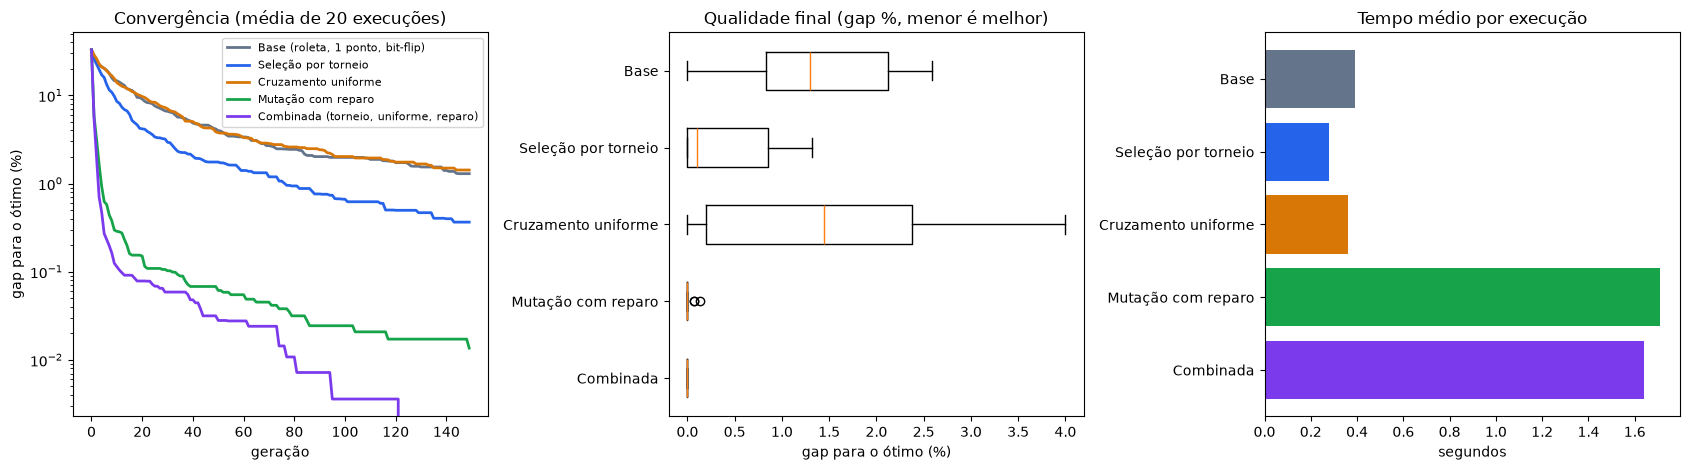

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8))
cores = ["#64748b", "#2563eb", "#d97706", "#16a34a", "#7c3aed"]
for cor, (nome, hist) in zip(cores, curvas.items()):
    media = np.mean(hist, axis=0)
    eixos[0].plot(100 * (OTIMO - media) / OTIMO, label=nome, color=cor, lw=2)
eixos[0].set(title="Convergência (média de 20 execuções)", xlabel="geração", ylabel="gap para o ótimo (%)",
             yscale="log")
eixos[0].legend(fontsize=8)
dados = [resultados.loc[resultados.configuracao == n, "gap_pct"] for n in CONFIGURACOES]
eixos[1].boxplot(dados, tick_labels=[n.split(" (")[0] for n in CONFIGURACOES], orientation="horizontal")
eixos[1].set(title="Qualidade final (gap %, menor é melhor)", xlabel="gap para o ótimo (%)")
eixos[2].barh([n.split(" (")[0] for n in CONFIGURACOES], resumo["tempo_medio_s"], color=cores)
eixos[2].set(title="Tempo médio por execução", xlabel="segundos")
eixos[2].invert_yaxis(); eixos[1].invert_yaxis()
plt.tight_layout()
plt.savefig(DOCS / "ag_comparacao_resultados.png", dpi=130)
plt.show()

## 6. Melhor solução encontrada
Detalhe da solução da configuração com menor *gap* médio, comparada à solução exata.

In [6]:
melhor_config = resumo["gap_medio_pct"].idxmin()
sel, cruz, mut = CONFIGURACOES[melhor_config]
r = executar_ag(sel, cruz, mut, semente=0)
escolhidas = itens[r["x"] == 1].copy()
print(f"Configuração: {melhor_config}")
print(f"Receita: R$ {r['valor']:,.0f} (ótimo R$ {OTIMO:,.0f}) | água {agua @ r['x']:.0f}/{A} m³ | "
      f"custo R$ {custo @ r['x']:.0f}/{C} | {len(escolhidas)} intervenções")
print("Coincide com o ótimo exato:", bool((r["x"] == x_otimo).all()))
escolhidas.groupby("intervencao").agg(qtd=("item", "count"), agua_m3=("agua_m3", "sum"),
                                      custo_rs=("custo_rs", "sum"), receita_rs=("receita_rs", "sum"))

Configuração: Combinada (torneio, uniforme, reparo)
Receita: R$ 44,480 (ótimo R$ 44,480) | água 5650/5650 m³ | custo R$ 24400/24500 | 15 intervenções
Coincide com o ótimo exato: True


,qtd,agua_m3,custo_rs,receita_rs
intervencao,,,,
adubacao,5,0,12700,16932
calagem,4,0,6900,8010
irrigacao,6,5650,4800,19538


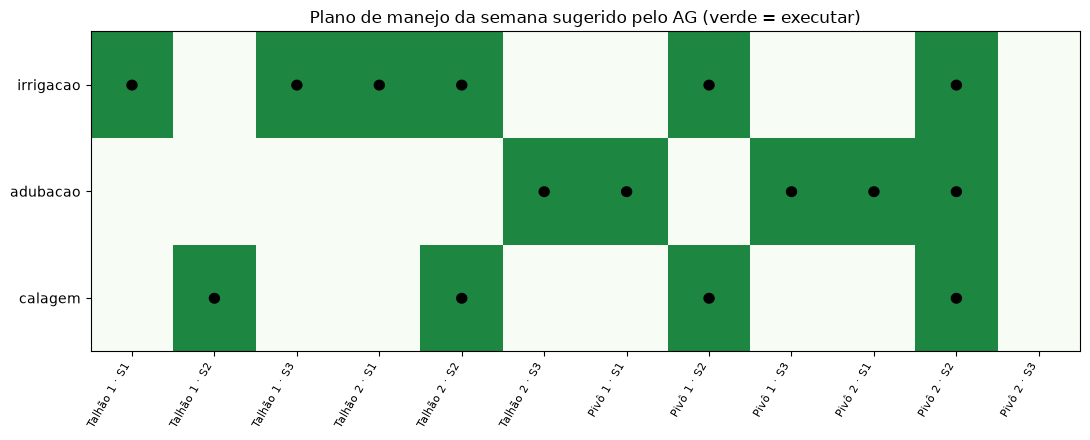

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
plano = itens.assign(escolhida=r["x"]).pivot_table(index="setor", columns="intervencao", values="escolhida",
                                                   aggfunc="max", sort=False)
ax.imshow(plano.T.values, cmap="Greens", aspect="auto", vmin=0, vmax=1.3)
ax.set_xticks(range(len(plano.index)), plano.index, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(plano.columns)), plano.columns)
for (j, i), v in np.ndenumerate(plano.T.values):
    ax.text(i, j, "●" if v else "", ha="center", va="center", fontsize=11)
ax.set_title("Plano de manejo da semana sugerido pelo AG (verde = executar)")
plt.tight_layout(); plt.savefig(DOCS / "ag_plano_manejo.png", dpi=130); plt.show()

## 7. Discussão e conclusão
**Qualidade.** A versão base (roleta + 1 ponto + bit-flip) ficou, em média, a cerca de 1,3% do ótimo e
encontrou o ótimo exato em apenas 1 das 20 execuções. A roleta exerce pouca pressão seletiva quando as
aptidões são parecidas (todas as soluções viáveis valem entre R$ 40 mil e R$ 44 mil), e o bit-flip gera
muitos filhos inviáveis, que a penalidade descarta.

**selection() — torneio.** Trocar a roleta pelo torneio (k=3) reduziu o gap médio para cerca de 0,4% e
elevou os acertos do ótimo para 9/20, sem custo extra de tempo (o torneio compara só 3 indivíduos, enquanto
a roleta normaliza a população inteira).

**crossover() — uniforme.** Sozinho, o cruzamento uniforme **não melhorou** o resultado (gap ≈ 1,4%): ele
mistura mais os genes e, com a roleta fraca, aumenta a quantidade de filhos inviáveis. Mostra que alterar
uma função isolada nem sempre ajuda.

**mutation() — reparo guloso.** Foi a mudança de maior impacto: gap ≈ 0,01% e 17/20 ótimos, porque todo
filho passa a ser viável e é "completado" com as intervenções de maior receita por recurso. O preço é o
tempo: cerca de 5 vezes mais lento por execução, pois o reparo testa a viabilidade item a item.

**Combinada.** Torneio + uniforme + reparo achou o ótimo nas **20 execuções**, convergindo em média por
volta da geração 50 (contra ~96 da base). O cruzamento uniforme, inútil sozinho, passa a ajudar quando o
reparo elimina as soluções inviáveis que ele criava.

**Tempo × qualidade.** Para 36 intervenções a programação dinâmica resolve o problema em milissegundos,
então o AG não é necessário aqui; ele se justifica quando o problema cresce (centenas de setores, mais
restrições como mão de obra e máquinas, custos não inteiros, objetivos múltiplos), cenário em que a PD
explode em memória. A escolha recomendada para a FarmTech é a **configuração combinada**: ~1,6 s por
execução é irrelevante para um planejamento semanal, e a confiabilidade (20/20) é o que importa.

**Plano sugerido.** Com 5.650 m³ de água e R$ 24.500, o plano ótimo executa 15 intervenções (6 irrigações,
5 adubações e 4 calagens), usa toda a água e R$ 24.400 do orçamento, com receita esperada de R$ 44.480.

**Limitações.** Ganhos de produtividade simulados a partir dos dados da FarmTech; intervenções tratadas como
independentes (na prática irrigar e adubar o mesmo setor tem efeito combinado); preços fixos da saca.